<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h1 style="text-align: center; color: #f6068aff; margin: 0;">Recommender System Project</h1>
    <h4 style="text-align: center; color: #f6068aff; margin: 0;">Created by Mohammad Amani</h4>
    <img src="tehran_data.png" alt="Logo" style="position: absolute; top: 0; right: 10px; height: 50px;">
</div>

<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h3 style="text-align: left; color: #f6068aff; margin: 0;">Import libraies</h3>
</div>

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display, HTML
import implicit
from sklearn.feature_extraction.text import TfidfVectorizer

import sys
import os

sys.path.append(os.path.abspath('..'))

c:\Users\mohammad\Desktop\RecommendPrject\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h3 style="text-align: left; color: #f6068aff; margin: 0;">Data processing</h3>
</div>

In [2]:
ratings_path = './data/raw/rating.csv'
anime_path = './data/raw/anime.csv'

print("Loading datasets into memory...\n")
ratings = pd.read_csv(ratings_path)
animes = pd.read_csv(anime_path)

print("=== Datasets Shape ===")
print(f"Ratings shape: {ratings.shape[0]:,} rows, {ratings.shape[1]} columns")
print(f"Animes shape:  {animes.shape[0]:,} rows, {animes.shape[1]} columns\n")

print("=== Missing Values Report ===")
print("Anime DataFrame Nulls:")
anime_nulls = animes.isnull().sum()
print(anime_nulls[anime_nulls > 0])

print("\nRatings DataFrame Nulls:")
rating_nulls = ratings.isnull().sum()
if rating_nulls.sum() == 0:
    print("No null values found in Ratings DataFrame.\n")
else:
    print(rating_nulls[rating_nulls > 0])

# The '-1' Challenge Analysis
print("\n=== The '-1' Rating Analysis ===")
total_ratings_count = len(ratings)
minus_one_count = (ratings['rating'] == -1).sum()
minus_one_percentage = (minus_one_count / total_ratings_count) * 100

print(f"Total '-1' records: {minus_one_count:,}")
print(f"Percentage of '-1' records: {minus_one_percentage:.2f}% of entire dataset")

Loading datasets into memory...

=== Datasets Shape ===
Ratings shape: 7,813,737 rows, 3 columns
Animes shape:  12,294 rows, 7 columns

=== Missing Values Report ===
Anime DataFrame Nulls:
genre      62
type       25
rating    230
dtype: int64

Ratings DataFrame Nulls:
No null values found in Ratings DataFrame.


=== The '-1' Rating Analysis ===
Total '-1' records: 1,476,496
Percentage of '-1' records: 18.90% of entire dataset


<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h4 style="text-align: left; color: #f6068aff; margin: 0;">Handling (-1) and missing values</h4>
</div>

In [3]:
from src.data_processor import AnimeDataPipeline

pipeline = AnimeDataPipeline(ratings_path=ratings_path, anime_path=anime_path, neg_ratio=4, random_state=1)

print("Step 1: Cleaning anime metadata and merging...")
animes_clean = pipeline._clean_anime_metadata()
merged_base = pipeline.ratings.merge(animes_clean, on='anime_id', how='inner')

print("Step 2: Processing Explicit Ratings (1 to 10)...")
explicit_clean, user_genre_avg = pipeline._process_explicit_ratings(merged_base)

print("Step 3: Processing Implicit Ratings (-1) with strict genre rule...")
implicit_clean = pipeline._process_implicit_ratings(merged_base, user_genre_avg)

print("Step 4: Combining processed datasets...")
explicit_clean = explicit_clean[['user_id', 'anime_id', 'attracted']]
processed_ratings = pd.concat([explicit_clean, implicit_clean], ignore_index=True)

print("\n=== Processing Complete ===")
print(f"Explicit records processed: {len(explicit_clean):,}")
print(f"Implicit records processed: {len(implicit_clean):,}")
print(f"Total 'attracted' (1) count: {(processed_ratings['attracted'] == 1).sum():,}")
print(f"Total 'not attracted' (0) count: {(processed_ratings['attracted'] == 0).sum():,}")
print(f"Total records ready for negative sampling: {len(processed_ratings):,}")

Loading datasets...
Step 1: Cleaning anime metadata and merging...
Step 2: Processing Explicit Ratings (1 to 10)...
Step 3: Processing Implicit Ratings (-1) with strict genre rule...
Step 4: Combining processed datasets...

=== Processing Complete ===
Explicit records processed: 6,337,239
Implicit records processed: 1,476,488
Total 'attracted' (1) count: 5,806,165
Total 'not attracted' (0) count: 2,007,562
Total records ready for negative sampling: 7,813,727


<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h4 style="text-align: left; color: #f6068aff; margin: 0;">Negative Sampling</h4>
</div>

In [4]:
print("Step 5: Generating Negative Samples (Unseen Animes)...")
negatives_df = pipeline._generate_negative_samples(processed_ratings)

print("Step 6: Finalizing Dataset (Concatenation & Shuffling)...")
final_dataset = pd.concat([processed_ratings, negatives_df], ignore_index=True)

final_dataset = final_dataset.sample(frac=1.0, random_state=42).reset_index(drop=True)

print("\n=== Final Dataset Overview ===")
print(f"Total rows after negative sampling: {len(final_dataset):,}")

print("\nClass Distribution (attracted):")
print(final_dataset['attracted'].value_counts(normalize=True).round(4))

# save to parquet for high-performance loading in the modeling phase
output_path = './data/processed/collabrative_final_training_data.parquet'
final_dataset.to_parquet(output_path, index=False)
print(f"\nSaved final training dataset to: {output_path}")

Step 5: Generating Negative Samples (Unseen Animes)...
Generating negative samples...
Step 6: Finalizing Dataset (Concatenation & Shuffling)...

=== Final Dataset Overview ===
Total rows after negative sampling: 31,038,387

Class Distribution (attracted):
attracted
0    0.8129
1    0.1871
Name: proportion, dtype: float64

Saved final training dataset to: ./data/processed/collabrative_final_training_data.parquet


<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h3 style="text-align: left; color: #f6068aff; margin: 0;">Modeling</h3>
</div>

<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h4 style="text-align: left; color: #f6068aff; margin: 0;">Memory-based Collaborative Filtering</h4>
</div>

In [5]:
print("Step 1: Loading the prepared Parquet dataset...")
df = pd.read_parquet('./data/processed/collabrative_final_training_data.parquet')

print("Step 2: Mapping IDs to contiguous indices for sparse matrix...")
user_cat = df['user_id'].astype('category')
anime_cat = df['anime_id'].astype('category')

user_indices = user_cat.cat.codes
anime_indices = anime_cat.cat.codes

anime_id_map = dict(enumerate(anime_cat.cat.categories))
anime_id_reverse_map = {v: k for k, v in anime_id_map.items()}

print("Step 3: Building the Sparse User-Item Matrix...")
sparse_user_item = csr_matrix(
    (df['attracted'], (user_indices, anime_indices)), 
    shape=(user_indices.max() + 1, anime_indices.max() + 1)
)

matrix_size_mb = (sparse_user_item.data.nbytes + sparse_user_item.indptr.nbytes + sparse_user_item.indices.nbytes) / (1024 * 1024)
print(f"Sparse matrix shape: {sparse_user_item.shape} (Users x Animes)")
print(f"Sparse matrix RAM usage: {matrix_size_mb:.2f} MB")

print("Step 4: Computing Item-Item Cosine Similarity...")
sparse_item_user = sparse_user_item.T
item_similarity = cosine_similarity(sparse_item_user, dense_output=False)

print(f"Similarity matrix shape: {item_similarity.shape} (Animes x Animes)")
print("Item-Item Memory-based model is ready!")

Step 1: Loading the prepared Parquet dataset...
Step 2: Mapping IDs to contiguous indices for sparse matrix...
Step 3: Building the Sparse User-Item Matrix...
Sparse matrix shape: (73515, 12294) (Users x Animes)
Sparse matrix RAM usage: 355.49 MB
Step 4: Computing Item-Item Cosine Similarity...
Similarity matrix shape: (12294, 12294) (Animes x Animes)
Item-Item Memory-based model is ready!


<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h4 style="text-align: left; color: #f6068aff; margin: 0;">Inference Engine</h4>
</div>

=== Running Inference for Sample User: 12 ===

--- User's Recently Liked Animes (Sample of 5) ---
                                            name  \
0                                           Nana   
1  Darker than Black: Kuro no Keiyakusha Special   
2                            Mirai Shounen Conan   
3             Code Geass: Hangyaku no Lelouch R2   
4                               Sword Art Online   

                                               genre  
0  Comedy, Drama, Music, Romance, Shoujo, Slice o...  
1                             Comedy, Parody, Sci-Fi  
2                           Adventure, Drama, Sci-Fi  
3  Action, Drama, Mecha, Military, Sci-Fi, Super ...  
4          Action, Adventure, Fantasy, Game, Romance  

--- Top 10 Recommended Animes ---
                         name  similarity_score
0         Fullmetal Alchemist          6.960435
1                Angel Beats!          6.922379
2                   Toradora!          6.727002
3                  Elfen Lied   

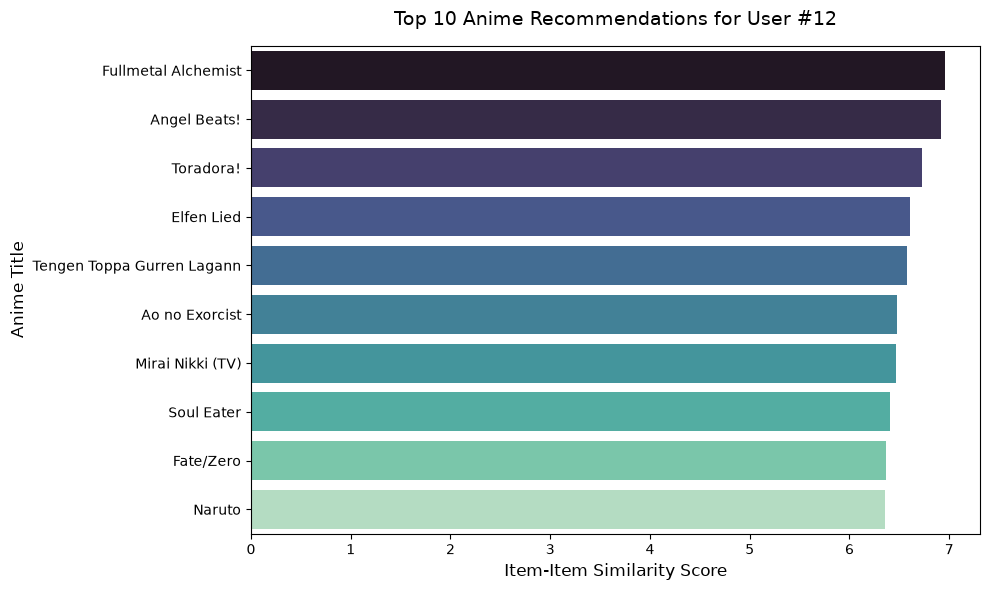

In [6]:
def get_item_item_recommendations(target_user_id, user_item_matrix, item_sim_matrix, 
                                  raw_interactions_df, animes_df, user_to_idx, 
                                  idx_to_anime, top_k=10):
    
    if target_user_id not in user_to_idx:
        print("Error: User not found in the dataset.")
        return None, None
        
    user_idx = user_to_idx[target_user_id]
    user_vector = user_item_matrix[user_idx, :]
    
    rec_scores = user_vector.dot(item_sim_matrix)
    rec_scores = rec_scores.toarray().flatten()
    
    user_history = raw_interactions_df[raw_interactions_df['user_id'] == target_user_id]['anime_id'].values
    anime_to_idx = {v: k for k, v in idx_to_anime.items()}
    history_indices = [anime_to_idx[aid] for aid in user_history if aid in anime_to_idx]
    
    # mask seen items with 0 score
    rec_scores[history_indices] = 0.0
    
    top_indices = rec_scores.argsort()[::-1][:top_k]
    top_scores = rec_scores[top_indices]
    
    recommended_anime_ids = [idx_to_anime[idx] for idx in top_indices]
    rec_df = pd.DataFrame({
        'anime_id': recommended_anime_ids,
        'similarity_score': top_scores
    })
    
    rec_df = rec_df.merge(animes_df[['anime_id', 'name', 'genre']], on='anime_id', how='left')
    
    liked_history = raw_interactions_df[(raw_interactions_df['user_id'] == target_user_id) & 
                                        (raw_interactions_df['attracted'] == 1)]
    liked_df = liked_history.merge(animes_df[['anime_id', 'name', 'genre']], on='anime_id', how='left')
    
    return liked_df, rec_df


user_id_map = dict(zip(df['user_id'], user_indices))

# find a suitable sample user (someone who has liked at least 15 animes)
user_likes_count = df[df['attracted'] == 1].groupby('user_id').size()
suitable_users = user_likes_count[(user_likes_count >= 15) & (user_likes_count <= 40)].index
sample_user_id = suitable_users[0] 

print(f"=== Running Inference for Sample User: {sample_user_id} ===\n")

liked_animes, recommendations = get_item_item_recommendations(
    target_user_id=sample_user_id,
    user_item_matrix=sparse_user_item,
    item_sim_matrix=item_similarity,
    raw_interactions_df=df,
    animes_df=animes,
    user_to_idx=user_id_map,
    idx_to_anime=anime_id_map,
    top_k=10
)

print("--- User's Recently Liked Animes (Sample of 5) ---")
print(liked_animes[['name', 'genre']].head(5))
print("\n--- Top 10 Recommended Animes ---")
print(recommendations[['name', 'similarity_score']])

# Plotting the Recommendations
plt.figure(figsize=(10, 6))
sns.barplot(x='similarity_score', y='name', data=recommendations, palette='mako', hue='name', legend=False)

plt.title(f"Top 10 Anime Recommendations for User #{sample_user_id}", fontsize=14, pad=15)
plt.xlabel("Item-Item Similarity Score", fontsize=12)
plt.ylabel("Anime Title", fontsize=12)
# plt.gca().invert_yaxis() 
plt.tight_layout()
plt.show()

<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h3 style="text-align: left; color: #f6068aff; margin: 0;">Evaluation</h3>
</div>

In [7]:
from src.evaluator import ModelEvaluator

print("Step 1: Initializing Evaluator and Splitting Data...")
evaluator = ModelEvaluator(k=10)
df = pd.read_parquet('./data/processed/collabrative_final_training_data.parquet')

# split data: 20% of positive interactions go to test
train_df, test_df = evaluator.train_test_split(df, test_ratio=0.2, random_state=42)

print("\nStep 2: Rebuilding Item-Item Model on TRAIN Data...")
user_cat = train_df['user_id'].astype('category')
anime_cat = train_df['anime_id'].astype('category')

user_indices = user_cat.cat.codes
anime_indices = anime_cat.cat.codes

anime_id_map = dict(enumerate(anime_cat.cat.categories))
user_id_map = dict(zip(train_df['user_id'], user_indices))

sparse_train_matrix = csr_matrix(
    (train_df['attracted'], (user_indices, anime_indices)), 
    shape=(user_indices.max() + 1, anime_indices.max() + 1)
)

item_similarity = cosine_similarity(sparse_train_matrix.T, dense_output=False)

print("\nStep 3: Generating Recommendations for Test Users...")
test_users = test_df['user_id'].unique()
total_catalog_items = set(df['anime_id'].unique())
recommendations_dict = {}

# inference loop for all test users
for uid in test_users:
    if uid not in user_id_map:
        continue
        
    u_idx = user_id_map[uid]
    user_vec = sparse_train_matrix[u_idx, :]
    
    scores = user_vec.dot(item_similarity).toarray().flatten()
    
    # don't recommend what they've already seen in training
    train_history_indices = user_vec.nonzero()[1]
    scores[train_history_indices] = 0.0
    
    top_indices = scores.argsort()[::-1][:10]
    recommendations_dict[uid] = [anime_id_map[idx] for idx in top_indices]

print("\nStep 4: Evaluating the Model...")
metrics = evaluator.evaluate(
    model_name="Memory-based CF (Item-Item)",
    recommendations_dict=recommendations_dict,
    test_df=test_df,
    total_catalog_items=total_catalog_items
)

print("\n=== Global Model Leaderboard ===")
leaderboard = []
leaderboard.append(metrics)

leaderboard_df = pd.DataFrame(leaderboard)
print(leaderboard_df.to_string(index=False))

Step 1: Initializing Evaluator and Splitting Data...
Starting User-centric Train/Test Split...
Split Complete! Train shape: (29877662, 3), Test shape: (1160725, 3)

Step 2: Rebuilding Item-Item Model on TRAIN Data...

Step 3: Generating Recommendations for Test Users...

Step 4: Evaluating the Model...

=== Global Model Leaderboard ===
                      Model  Precision@10  Recall@10  F1-Score@10   MAP@10  NDCG@10  Catalog_Coverage
Memory-based CF (Item-Item)       0.20859    0.20498     0.153266 0.186143 0.300256          0.191964


<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h4 style="text-align: left; color: #f6068aff; margin: 0;">Memory Base Model Sanity Check</h4>
</div>

In [8]:
print("Step 1: Selecting a suitable sample user for qualitative analysis...")
# find users who have between 3 and 10 items in the test set to make the comparison visually interesting
test_user_counts = test_df.groupby('user_id').size()
suitable_test_users = test_user_counts[(test_user_counts >= 3) & (test_user_counts <= 10)].index
sample_uid = suitable_test_users[0]

train_history_ids = train_df[(train_df['user_id'] == sample_uid) & (train_df['attracted'] == 1)]['anime_id'].tolist()
test_actual_ids = test_df[test_df['user_id'] == sample_uid]['anime_id'].tolist()
recommended_ids = recommendations_dict[sample_uid]

# map IDs to anime names
anime_mapping = dict(zip(animes['anime_id'], animes['name']))

# show up to 10 items for train history to keep the table compact
train_names = [anime_mapping.get(aid, f"Anime {aid}") for aid in train_history_ids][:10] 
test_names = [anime_mapping.get(aid, f"Anime {aid}") for aid in test_actual_ids]
rec_names = [anime_mapping.get(aid, f"Anime {aid}") for aid in recommended_ids]

# find Hits
hits = set(test_names).intersection(set(rec_names))

max_len = max(len(train_names), len(test_names), len(rec_names))

def pad_list(lst, length):
    return lst + [""] * (length - len(lst))

compare_df = pd.DataFrame({
    'Train History (Taste Profile)': pad_list(train_names, max_len),
    'Ground Truth (Actual Future Likes)': pad_list(test_names, max_len),
    'Model Recommendations (Top 10)': pad_list(rec_names, max_len)
})

# apply CSS styling to highlight Hits in Green
def highlight_hits(val):
    if val in hits and val != "":
        return 'background-color: #d4edda; color: #155724; font-weight: bold;' # Green highlight
    return ''

print(f"\n=== Qualitative Analysis for User #{sample_uid} ===")
print(f"Total Hits in Top-10: {len(hits)}")
print("Highlight: Items shaded in GREEN were successfully predicted by the model.\n")

# pandas styler to render the beautiful table
try:
    styled_df = compare_df.style.map(highlight_hits, subset=['Ground Truth (Actual Future Likes)', 'Model Recommendations (Top 10)'])
except AttributeError:
    styled_df = compare_df.style.applymap(highlight_hits, subset=['Ground Truth (Actual Future Likes)', 'Model Recommendations (Top 10)'])

styled_df = styled_df.set_properties(**{'text-align': 'left', 'font-size': '13px', 'border': '1px solid lightgrey'}) \
                     .set_table_styles([{'selector': 'th', 'props': [('font-size', '14px'), ('text-align', 'center'), ('background-color', '#f4f6f9'), ('border', '1px solid lightgrey')]}])

# display the styled HTML table in Jupyter
display(styled_df)

Step 1: Selecting a suitable sample user for qualitative analysis...

=== Qualitative Analysis for User #12 ===
Total Hits in Top-10: 1
Highlight: Items shaded in GREEN were successfully predicted by the model.



,Train History (Taste Profile),Ground Truth (Actual Future Likes),Model Recommendations (Top 10)
0,Darker than Black: Kuro no Keiyakusha Gaiden,Code Geass: Boukoku no Akito 1 - Yokuryuu wa Maiorita,Code Geass: Hangyaku no Lelouch
1,Sword Art Online,Dragon Ball Kai,Angel Beats!
2,Fullmetal Alchemist: Brotherhood,Dragon Ball Z,Fullmetal Alchemist
3,Nana,Code Geass: Hangyaku no Lelouch,Durarara!!
4,Ouran Koukou Host Club,,Toradora!
5,Yamato Nadeshiko Shichihenge♥,,Elfen Lied
6,Code Geass: Hangyaku no Lelouch R2,,Tengen Toppa Gurren Lagann
7,Death Note,,Ao no Exorcist
8,Steins;Gate,,Mirai Nikki (TV)
9,Darker than Black: Kuro no Keiyakusha Special,,Soul Eater


<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h4 style="text-align: left; color: #f6068aff; margin: 0;">Model-based(BPR) Collaborative Filtering</h4>
</div>

In [9]:
print("Step 1: Initializing and Training BPR Model...")
# TODO: run a grid search to get better results. it's gonna effect hybrid model too.
bpr_model = implicit.bpr.BayesianPersonalizedRanking(
    factors=64, 
    learning_rate=0.01,
    iterations=100, 
    verify_negative_samples=True,
    random_state=42
)

bpr_model.fit(sparse_train_matrix)

print("\nStep 2: Generating Recommendations for Test Users...")
bpr_recommendations_dict = {}

# inference for test users
for uid in test_users:
    if uid not in user_id_map:
        continue
        
    u_idx = user_id_map[uid]
    
    # filter_already_liked_items=True automatically uses the train matrix to mask history!
    recommended_indices, scores = bpr_model.recommend(
        u_idx, 
        sparse_train_matrix[u_idx], 
        N=10, 
        filter_already_liked_items=True
    )
    
    # map the internal matrix indices back to actual anime_ids
    bpr_recommendations_dict[uid] = [anime_id_map[idx] for idx in recommended_indices]

print("\nStep 3: Evaluating the BPR Model...")
bpr_metrics = evaluator.evaluate(
    model_name="Model-based CF (BPR)",
    recommendations_dict=bpr_recommendations_dict,
    test_df=test_df,
    total_catalog_items=total_catalog_items
)

print("\n=== Updated Global Model Leaderboard ===")
leaderboard.append(bpr_metrics)
leaderboard_df = pd.DataFrame(leaderboard).sort_values(by='NDCG@10', ascending=False)
print(leaderboard_df.to_string(index=False))

Step 1: Initializing and Training BPR Model...


100%|██████████| 100/100 [04:06<00:00,  2.46s/it, train_auc=66.92%, skipped=11.95%]



Step 2: Generating Recommendations for Test Users...

Step 3: Evaluating the BPR Model...

=== Updated Global Model Leaderboard ===
                      Model  Precision@10  Recall@10  F1-Score@10   MAP@10  NDCG@10  Catalog_Coverage
       Model-based CF (BPR)      0.232687   0.193475     0.160723 0.196621 0.310400          0.365219
Memory-based CF (Item-Item)      0.208590   0.204980     0.153266 0.186143 0.300256          0.191964


<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h4 style="text-align: left; color: #f6068aff; margin: 0;">BPR Mpdel sanity check</h4>
</div>

In [10]:
bpr_recommended_ids = bpr_recommendations_dict[sample_uid]
bpr_rec_names = [anime_mapping.get(aid, f"Anime {aid}") for aid in bpr_recommended_ids]

# find hits for BPR
bpr_hits = set(test_names).intersection(set(bpr_rec_names))

# build the comparison DataFrame
compare_df_bpr = pd.DataFrame({
    'Train History (Taste Profile)': pad_list(train_names, max_len),
    'Ground Truth (Actual Future Likes)': pad_list(test_names, max_len),
    'BPR Recommendations (Top 10)': pad_list(bpr_rec_names, max_len)
})

# apply CSS styling for BPR Hits
def highlight_bpr_hits(val):
    if val in bpr_hits and val != "":
        return 'background-color: #d4edda; color: #155724; font-weight: bold;'
    return ''

print(f"\n=== BPR Qualitative Analysis for User #{sample_uid} ===")
print(f"Total Hits in Top-10: {len(bpr_hits)}")
print("Highlight: Items shaded in GREEN were successfully predicted by the BPR model.\n")

# Use Pandas Styler
try:
    # for newer Pandas versions
    styled_df_bpr = compare_df_bpr.style.map(highlight_bpr_hits, subset=['Ground Truth (Actual Future Likes)', 'BPR Recommendations (Top 10)'])
except AttributeError:
    # for older Pandas versions
    styled_df_bpr = compare_df_bpr.style.applymap(highlight_bpr_hits, subset=['Ground Truth (Actual Future Likes)', 'BPR Recommendations (Top 10)'])

styled_df_bpr = styled_df_bpr.set_properties(**{'text-align': 'left', 'font-size': '13px', 'border': '1px solid lightgrey'}) \
                             .set_table_styles([{'selector': 'th', 'props': [('font-size', '14px'), ('text-align', 'center'), ('background-color', '#f4f6f9'), ('border', '1px solid lightgrey')]}])

display(styled_df_bpr)


=== BPR Qualitative Analysis for User #12 ===
Total Hits in Top-10: 2
Highlight: Items shaded in GREEN were successfully predicted by the BPR model.



,Train History (Taste Profile),Ground Truth (Actual Future Likes),BPR Recommendations (Top 10)
0,Darker than Black: Kuro no Keiyakusha Gaiden,Code Geass: Boukoku no Akito 1 - Yokuryuu wa Maiorita,Fate/Zero
1,Sword Art Online,Dragon Ball Kai,Kuroshitsuji
2,Fullmetal Alchemist: Brotherhood,Dragon Ball Z,Soul Eater
3,Nana,Code Geass: Hangyaku no Lelouch,Dragon Ball Z
4,Ouran Koukou Host Club,,Fate/Zero 2nd Season
5,Yamato Nadeshiko Shichihenge♥,,Code Geass: Hangyaku no Lelouch
6,Code Geass: Hangyaku no Lelouch R2,,Kuroshitsuji II
7,Death Note,,Hellsing Ultimate
8,Steins;Gate,,Bleach
9,Darker than Black: Kuro no Keiyakusha Special,,Fullmetal Alchemist


<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h3 style="text-align: left; color: #f6068aff; margin: 0;">Hybrid Recommender Systems</h3>
</div>

<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h4 style="text-align: left; color: #f6068aff; margin: 0;">Content Engine</h4>
</div>

In [11]:
print("Step 1: Loading Data & Formatting Missing Values...")
animes = pd.read_csv('./data/raw/anime.csv')

# drop 'rating' column completely as discussed
if 'rating' in animes.columns:
    animes = animes.drop(columns=['rating'])

animes['episodes'] = animes['episodes'].replace('Unknown', np.nan)
animes['type'] = animes['type'].replace('Unknown', np.nan)
animes['episodes'] = pd.to_numeric(animes['episodes'], errors='coerce')

print("\nStep 2: Handling rows missing BOTH 'type' and 'episodes'...")
missing_both_mask = animes['type'].isna() & animes['episodes'].isna()
print(f"-> Number of rows missing BOTH 'type' and 'episodes': {missing_both_mask.sum()}")
animes = animes[~missing_both_mask].copy()

print("\nMissing values AFTER dropping the completely unknown rows:")
print(animes.isna().sum())

print("\nStep 3: Imputing 'type' based on 'episodes'...")
animes.loc[animes['type'].isna() & (animes['episodes'] == 1), 'type'] = 'Movie'
animes.loc[animes['type'].isna() & (animes['episodes'] > 1) & (animes['episodes'] <= 5), 'type'] = 'OVA'
animes.loc[animes['type'].isna() & (animes['episodes'] > 5), 'type'] = 'TV'

print("\nStep 4: Imputing 'episodes' based on 'type'...")
animes.loc[animes['episodes'].isna() & (animes['type'].isin(['Movie', 'OVA', 'Special'])), 'episodes'] = 1

tv_median = animes.loc[animes['type'] == 'TV', 'episodes'].median()
animes.loc[animes['episodes'].isna() & (animes['type'] == 'TV'), 'episodes'] = tv_median

animes['genre'] = animes['genre'].fillna('Unknown').str.replace(',', ' ')

animes['episodes'] = animes['episodes'].fillna(-1).astype(int)
animes['type'] = animes['type'].fillna('Unknown')

print("\nMissing values AFTER all smart imputations:")
print(animes.isna().sum())

print("\nStep 5: Feature Engineering (Meta-Document)...")
def categorize_episodes(ep):
    if ep <= 0:
        return 'Ep_Unknown'
    elif ep == 1:
        return 'Single_Release'  
    elif ep <= 13:
        return 'Short_Series'
    elif ep <= 26:
        return 'Standard_Series'
    else:
        return 'Long_Series'

animes['ep_bucket'] = animes['episodes'].apply(categorize_episodes)
animes['meta_text'] = animes['genre'] + " " + animes['type'] + " " + animes['ep_bucket']

print("\nStep 6: Aligning Metadata with Collaborative Matrix Indices...")
meta_dict = dict(zip(animes['anime_id'], animes['meta_text']))
aligned_meta_texts = [meta_dict.get(aid, "") for aid in anime_cat.cat.categories]

print("\nStep 7: Building TF-IDF and Content Similarity Matrix...")
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(aligned_meta_texts)
content_similarity = cosine_similarity(tfidf_matrix, dense_output=False)

print(f"\n✅ Content Engine Ready! Similarity Matrix Shape: {content_similarity.shape}")

Step 1: Loading Data & Formatting Missing Values...

Step 2: Handling rows missing BOTH 'type' and 'episodes'...
-> Number of rows missing BOTH 'type' and 'episodes': 25

Missing values AFTER dropping the completely unknown rows:
anime_id      0
name          0
genre        59
type          0
episodes    315
members       0
dtype: int64

Step 3: Imputing 'type' based on 'episodes'...

Step 4: Imputing 'episodes' based on 'type'...

Missing values AFTER all smart imputations:
anime_id    0
name        0
genre       0
type        0
episodes    0
members     0
dtype: int64

Step 5: Feature Engineering (Meta-Document)...

Step 6: Aligning Metadata with Collaborative Matrix Indices...

Step 7: Building TF-IDF and Content Similarity Matrix...

✅ Content Engine Ready! Similarity Matrix Shape: (12294, 12294)


<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h4 style="text-align: left; color: #f6068aff; margin: 0;">Grid Search</h4>
    <p>This grid search has a long runtime.<br> I ran it and alpha=0.75 had the best results.<br> If you want to do a grid search uncomment the cell.</p>
</div>

In [12]:
# import time

# print("Step 1: Setting up Hybrid Grid Search...")
# alphas_to_test = [0.65, 0.70, 0.75]

# hybrid_leaderboard = []
# best_alpha = None
# best_hybrid_metrics = None
# best_ndcg = -1

# content_similarity_csr = content_similarity.tocsr()

# user_factors = np.asarray(bpr_model.user_factors)
# item_factors = np.asarray(bpr_model.item_factors)

# def normalize_scores(scores):
#     s_min, s_max = scores.min(), scores.max()
#     if s_max == s_min:
#         return np.zeros_like(scores)
#     return (scores - s_min) / (s_max - s_min)

# print(f"Step 2: Starting Grid Search for alphas: {alphas_to_test}...\n")

# for alpha in alphas_to_test:
#     print(f"--- Evaluating Hybrid Model with alpha = {alpha} ---")
#     start_time = time.time()
    
#     hybrid_recommendations_dict = {}
    
#     for uid in test_users:
#         if uid not in user_id_map:
#             continue
            
#         u_idx = user_id_map[uid]
        
#         # --- 1. Collaborative Scores ---
#         raw_bpr_scores = user_factors[u_idx].dot(item_factors.T)
        
#         # --- 2. Content Scores ---
#         user_row = sparse_train_matrix[u_idx] 
#         num_history = user_row.nnz 
        
#         if num_history > 0:
#             raw_content_scores = (user_row.dot(content_similarity_csr) / num_history).toarray().flatten()
#         else:
#             raw_content_scores = np.zeros(content_similarity.shape[0])
            
#         # --- 3. Normalization ---
#         bpr_norm = normalize_scores(raw_bpr_scores)
#         content_norm = normalize_scores(raw_content_scores)
        
#         # --- 4. Hybrid Formula ---
#         hybrid_scores = (alpha * bpr_norm) + ((1 - alpha) * content_norm)
        
#         # --- 5. Masking & Top-10 ---
#         user_history_indices = user_row.indices
#         hybrid_scores[user_history_indices] = -np.inf
        
#         top_10_idx = np.argsort(hybrid_scores)[-10:][::-1]
#         hybrid_recommendations_dict[uid] = [anime_id_map[idx] for idx in top_10_idx]

#     hybrid_metrics = evaluator.evaluate(
#         model_name=f"Hybrid CF+Content (alpha={alpha})",
#         recommendations_dict=hybrid_recommendations_dict,
#         test_df=test_df,
#         total_catalog_items=total_catalog_items
#     )
    
#     hybrid_leaderboard.append(hybrid_metrics)
    
#     if hybrid_metrics['NDCG@10'] > best_ndcg:
#         best_ndcg = hybrid_metrics['NDCG@10']
#         best_alpha = alpha
#         best_hybrid_metrics = hybrid_metrics
        
#     elapsed_time = time.time() - start_time
#     print(f"✅ Completed alpha={alpha} in {elapsed_time:.2f} seconds.\n")

# print("=== Internal Hybrid Grid Search Results ===")
# hybrid_leaderboard_df = pd.DataFrame(hybrid_leaderboard).sort_values(by='NDCG@10', ascending=False)
# display(hybrid_leaderboard_df)

# print(f"\n🏆 Best Alpha found: {best_alpha} (Will be used for Global Leaderboard)")

<div style="position: relative; padding-bottom: 10px; border-bottom: 2px solid #3498DB;">
    <h4 style="text-align: left; color: #f6068aff; margin: 0;">Hybrid Model for Best Alpha and Sanity Check</h4>
</div>

In [13]:

final_alpha = 0.75
print(f"Step 1: Generating Final Hybrid Recommendations (alpha={final_alpha})...")

content_similarity_csr = content_similarity.tocsr()
user_factors = np.asarray(bpr_model.user_factors)
item_factors = np.asarray(bpr_model.item_factors)

def normalize_scores(scores):
    s_min, s_max = scores.min(), scores.max()
    if s_max == s_min:
        return np.zeros_like(scores)
    return (scores - s_min) / (s_max - s_min)

final_hybrid_recs = {}

for uid in test_users:
    if uid not in user_id_map:
        continue
        
    u_idx = user_id_map[uid]
    
    # collaborative scores (BPR)
    raw_bpr_scores = user_factors[u_idx].dot(item_factors.T)
    
    # content scores
    user_row = sparse_train_matrix[u_idx]
    num_history = user_row.nnz
    
    if num_history > 0:
        raw_content_scores = (user_row.dot(content_similarity_csr) / num_history).toarray().flatten()
    else:
        raw_content_scores = np.zeros(content_similarity.shape[0])
        
    bpr_norm = normalize_scores(raw_bpr_scores)
    content_norm = normalize_scores(raw_content_scores)
    
    hybrid_scores = (final_alpha * bpr_norm) + ((1 - final_alpha) * content_norm)
    
    user_history_indices = user_row.indices
    hybrid_scores[user_history_indices] = -np.inf
    
    top_10_idx = np.argsort(hybrid_scores)[-10:][::-1]
    final_hybrid_recs[uid] = [anime_id_map[idx] for idx in top_10_idx]

print("Step 2: Evaluating the Final Hybrid Model...")
final_hybrid_metrics = evaluator.evaluate(
    model_name=f"Hybrid CF+Content (alpha={final_alpha})",
    recommendations_dict=final_hybrid_recs,
    test_df=test_df,
    total_catalog_items=total_catalog_items
)

leaderboard.append(final_hybrid_metrics)

print("\n=== Final Global Model Leaderboard ===")
final_leaderboard_df = pd.DataFrame(leaderboard).sort_values(by='NDCG@10', ascending=False)
display(final_leaderboard_df)
print(f"\nStep 3: Final Sanity Check for Sample User #{sample_uid} (alpha={final_alpha})...")

hybrid_rec_names = [anime_mapping.get(aid, f"Anime {aid}") for aid in final_hybrid_recs[sample_uid]]
hybrid_hits = set(test_names).intersection(set(hybrid_rec_names))

compare_df_hybrid = pd.DataFrame({
    'Train History (Taste Profile)': pad_list(train_names, max_len),
    'Ground Truth (Actual Future Likes)': pad_list(test_names, max_len),
    f'Hybrid Recs (alpha={final_alpha})': pad_list(hybrid_rec_names, max_len)
})

def highlight_hybrid_hits(val):
    if val in hybrid_hits and val != "":
        return 'background-color: #d4edda; color: #155724; font-weight: bold;'
    return ''

print(f"Total Hits in Top-10: {len(hybrid_hits)}")
print("Highlight: Items shaded in GREEN were successfully predicted by the Hybrid model.\n")

try:
    styled_df_hybrid = compare_df_hybrid.style.map(
        highlight_hybrid_hits, 
        subset=['Ground Truth (Actual Future Likes)', f'Hybrid Recs (alpha={final_alpha})']
    )
except AttributeError:
    styled_df_hybrid = compare_df_hybrid.style.applymap(
        highlight_hybrid_hits, 
        subset=['Ground Truth (Actual Future Likes)', f'Hybrid Recs (alpha={final_alpha})']
    )

styled_df_hybrid = styled_df_hybrid.set_properties(**{'text-align': 'left', 'font-size': '13px', 'border': '1px solid lightgrey'}) \
                             .set_table_styles([{'selector': 'th', 'props': [('font-size', '14px'), ('text-align', 'center'), ('background-color', '#f4f6f9'), ('border', '1px solid lightgrey')]}])

display(styled_df_hybrid)

Step 1: Generating Final Hybrid Recommendations (alpha=0.75)...
Step 2: Evaluating the Final Hybrid Model...

=== Final Global Model Leaderboard ===


,Model,Precision@10,Recall@10,F1-Score@10,MAP@10,NDCG@10,Catalog_Coverage
2,Hybrid CF+Content (alpha=0.75),0.233944,0.199885,0.163170,0.201112,0.316348,0.316984
1,Model-based CF (BPR),0.232687,0.193475,0.160723,0.196621,0.310400,0.365219
0,Memory-based CF (Item-Item),0.208590,0.204980,0.153266,0.186143,0.300256,0.191964



Step 3: Final Sanity Check for Sample User #12 (alpha=0.75)...
Total Hits in Top-10: 3
Highlight: Items shaded in GREEN were successfully predicted by the Hybrid model.



,Train History (Taste Profile),Ground Truth (Actual Future Likes),Hybrid Recs (alpha=0.75)
0,Darker than Black: Kuro no Keiyakusha Gaiden,Code Geass: Boukoku no Akito 1 - Yokuryuu wa Maiorita,Code Geass: Hangyaku no Lelouch
1,Sword Art Online,Dragon Ball Kai,Dragon Ball Z
2,Fullmetal Alchemist: Brotherhood,Dragon Ball Z,Soul Eater
3,Nana,Code Geass: Hangyaku no Lelouch,Kuroshitsuji
4,Ouran Koukou Host Club,,Bleach
5,Yamato Nadeshiko Shichihenge♥,,Fate/Zero
6,Code Geass: Hangyaku no Lelouch R2,,Dragon Ball Kai
7,Death Note,,Fullmetal Alchemist
8,Steins;Gate,,Fate/Zero 2nd Season
9,Darker than Black: Kuro no Keiyakusha Special,,Claymore
